In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    cohen_kappa_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from xgboost import XGBClassifier

- **Dataset:** WBCAtt (NeurIPS 2023), containing 10,298 white blood cell records.
- **Objective:** Predict cell type using 11 categorical morphological attributes.
- **Target classes:** Basophil, Eosinophil, Lymphocyte, Monocyte and Neutrophil.
- **Data splits:** Training: 6,169; validation: 1,030; test: 3,099 records.
- **Preprocessing:** LabelEncoder for the target and OneHotEncoder for features, both fitted only on training data.
- **Models:** Logistic Regression, Random Forest, ExtraTrees, HistGradientBoosting and XGBoost.
- **Primary evaluation metric:** Macro-F1.
- **Source:** [Official dataset](https://github.com/apple2373/wbcatt) | [Dataset paper](https://arxiv.org/abs/2306.13531)
- **Processed datasets** [Train](https://drive.google.com/file/d/1gS3p3L54JCDEy2M1H9N7wVb9UoosJo8m/view?usp=drive_link) | [Test](https://drive.google.com/file/d/1c90eiuANDSHJUhz8wDjoD26zFXabVtpW/view?usp=drive_link) | [Validation](https://drive.google.com/file/d/1HCCddqW7BBUwlkj7qsj2Hj-DWOtbfOfc/view?usp=drive_link)

In [3]:
PATH = "/content/drive/MyDrive/Datasets/wbcatt"
TARGET = "label"
SEED = 42

In [4]:
train_df = pd.read_csv(f"{PATH}/pbc_attr_v1_train.csv")
test_df = pd.read_csv(f"{PATH}/pbc_attr_v1_test.csv")
val_df = pd.read_csv(f"{PATH}/pbc_attr_v1_val.csv")

display(train_df.head())

,label,cell_size,cell_shape,nucleus_shape,nuclear_cytoplasmic_ratio,chromatin_density,cytoplasm_vacuole,cytoplasm_texture,cytoplasm_colour,granule_type,granule_colour,granularity
0,Neutrophil,big,round,unsegmented-band,low,densely,no,clear,light blue,small,pink,yes
1,Neutrophil,big,irregular,unsegmented-band,low,densely,no,clear,light blue,small,pink,yes
2,Neutrophil,big,irregular,unsegmented-band,low,densely,no,clear,light blue,small,pink,yes
3,Neutrophil,big,irregular,unsegmented-band,low,densely,no,clear,light blue,small,pink,yes
4,Neutrophil,small,round,unsegmented-round,low,densely,no,clear,light blue,small,pink,yes


In [5]:
train_df.shape

(6169, 12)

In [6]:
class_counts = train_df[TARGET].value_counts().sort_index()

display(class_counts.to_frame())

,count
label,
Basophil,744
Eosinophil,1876
Lymphocyte,736
Monocyte,829
Neutrophil,1984


In [7]:
train_df.isnull().sum()

,0
label,0
cell_size,0
cell_shape,0
nucleus_shape,0
nuclear_cytoplasmic_ratio,0
chromatin_density,0
cytoplasm_vacuole,0
cytoplasm_texture,0
cytoplasm_colour,0
granule_type,0


**Label and Feature Column Divide**

In [8]:
X_train = train_df.drop(columns=[TARGET])
X_val = val_df.drop(columns=[TARGET])
X_test = test_df.drop(columns=[TARGET])

y_train = train_df[TARGET]
y_val = val_df[TARGET]
y_test = test_df[TARGET]

print('Train:', X_train.shape, '| labels:', y_train.shape)
print('Validation:', X_val.shape, '| labels:', y_val.shape)
print('Test:', X_test.shape, '| labels:', y_test.shape)

Train: (6169, 11) | labels: (6169,)
Validation: (1030, 11) | labels: (1030,)
Test: (3099, 11) | labels: (3099,)


**preprocessing**

In [9]:
lb_encoder = LabelEncoder()
y_train = lb_encoder.fit_transform(y_train)

y_val = lb_encoder.transform(y_val)
y_test = lb_encoder.transform(y_test)

In [10]:
class_name = lb_encoder.classes_.tolist()
class_ids = np.arange(len(class_name))

label_mapping = pd.DataFrame({'class_id': class_ids, 'label': class_name})
display(label_mapping)

,class_id,label
0,0,Basophil
1,1,Eosinophil
2,2,Lymphocyte
3,3,Monocyte
4,4,Neutrophil


In [11]:
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

X_train_encoded = ohe.fit_transform(X_train)
X_val_encoded = ohe.transform(X_val)
X_test_encoded = ohe.transform(X_test)

print('Train:', X_train_encoded.shape)
print('Validation:', X_val_encoded.shape)
print('Test:', X_test_encoded.shape)

Train: (6169, 31)
Validation: (1030, 31)
Test: (3099, 31)


**Train and evaluation**

In [12]:
def evaluate(y_true, y_pred):
    metrics = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),
        "Macro precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Weighted precision": precision_score(y_true, y_pred, average="weighted", zero_division=0),
        "Weighted recall": recall_score(y_true, y_pred, average="weighted", zero_division=0),
        "Weighted F1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Cohen kappa": cohen_kappa_score(y_true, y_pred)   
    }
    return metrics

In [13]:
splits = {
    "Train": (X_train_encoded, y_train),
    "Validation": (X_val_encoded, y_val),
    "Test": (X_test_encoded, y_test),
}

models = {
    "Logistic Regression" : LogisticRegression(max_iter=1500, random_state=SEED),
    "RandomForest Classifier" : RandomForestClassifier(n_estimators=100, random_state=SEED),
    "ExtraTrees Classifier" : ExtraTreesClassifier(n_estimators=100, random_state=SEED),
    "Hist Classifier" : HistGradientBoostingClassifier(max_iter=1000, random_state=SEED),
    "XGB Classifier" : XGBClassifier(n_estimators=100, random_state=SEED)
}

In [14]:
results = []

for name, model in models.items():
    started = time.perf_counter()
    model.fit(X_train_encoded, y_train)
    training_seconds = time.perf_counter() - started
    
    for split_name, (X, y) in splits.items():
        predictions = model.predict(X)
        
        results.append({
            "Model": name,
            "Split": split_name,
            "Training Time (s)": training_seconds,
            **evaluate(y, predictions)
        })

In [15]:
results_df = pd.DataFrame(results)
display(results_df.round(4))

,Model,Split,Training Time (s),Accuracy,Balanced accuracy,Macro precision,Macro recall,Macro F1,Weighted precision,Weighted recall,Weighted F1,MCC,Cohen kappa
0,Logistic Regression,Train,0.0596,0.9909,0.9863,0.9859,0.9863,0.9861,0.9910,0.9909,0.9909,0.9880,0.9880
1,Logistic Regression,Validation,0.0596,0.9883,0.9850,0.9813,0.9850,0.9830,0.9886,0.9883,0.9884,0.9846,0.9846
2,Logistic Regression,Test,0.0596,0.9890,0.9833,0.9843,0.9833,0.9838,0.9890,0.9890,0.9890,0.9855,0.9855
3,RandomForest Classifier,Train,0.2773,0.9925,0.9888,0.9882,0.9888,0.9884,0.9926,0.9925,0.9925,0.9902,0.9902
4,RandomForest Classifier,Validation,0.2773,0.9874,0.9822,0.9808,0.9822,0.9814,0.9875,0.9874,0.9874,0.9833,0.9833
5,RandomForest Classifier,Test,0.2773,0.9881,0.9818,0.9827,0.9818,0.9823,0.9881,0.9881,0.9881,0.9842,0.9842
6,ExtraTrees Classifier,Train,0.2206,0.9925,0.9888,0.9882,0.9888,0.9884,0.9926,0.9925,0.9925,0.9902,0.9902
7,ExtraTrees Classifier,Validation,0.2206,0.9874,0.9826,0.9806,0.9826,0.9814,0.9877,0.9874,0.9874,0.9833,0.9833
8,ExtraTrees Classifier,Test,0.2206,0.9881,0.9818,0.9827,0.9818,0.9823,0.9881,0.9881,0.9881,0.9842,0.9842
9,Hist Classifier,Train,10.2797,0.9925,0.9888,0.9882,0.9888,0.9884,0.9926,0.9925,0.9925,0.9902,0.9902


In [16]:
def show_performance(name, y_true, y_pred):
    print(f"\n{name} — Classification Report\n")
    print(classification_report(
        y_true, y_pred, digits=4, zero_division=0
    ))

    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay.from_predictions(
        y_true,
        y_pred,
        cmap="Blues",
        colorbar=False,
        xticks_rotation=45,
        ax=ax
    )

    ax.set_title(f"{name} — Confusion Matrix")
    fig.tight_layout()
    plt.show()


Logistic Regression — Classification Report

              precision    recall  f1-score   support

    Basophil     0.9971    0.9914    0.9943       349
  Eosinophil     1.0000    1.0000    1.0000       927
  Lymphocyte     0.9566    0.9619    0.9592       367
    Monocyte     0.9728    0.9640    0.9684       445
  Neutrophil     0.9951    0.9990    0.9970      1011

    accuracy                         0.9890      3099
   macro avg     0.9843    0.9833    0.9838      3099
weighted avg     0.9890    0.9890    0.9890      3099



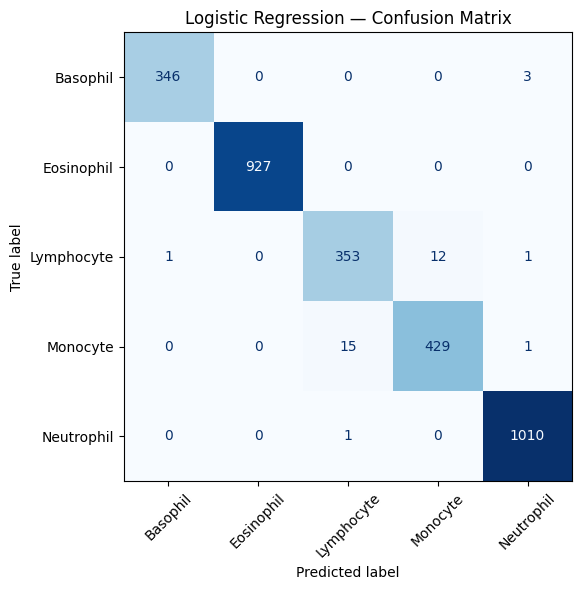

In [17]:
model = models["Logistic Regression"]
y_pred = model.predict(X_test_encoded)

show_performance(
    "Logistic Regression",
    lb_encoder.inverse_transform(y_test),
    lb_encoder.inverse_transform(y_pred)
)


RandomForest Classifier — Classification Report

              precision    recall  f1-score   support

    Basophil     0.9971    0.9914    0.9943       349
  Eosinophil     1.0000    1.0000    1.0000       927
  Lymphocyte     0.9488    0.9591    0.9539       367
    Monocyte     0.9727    0.9596    0.9661       445
  Neutrophil     0.9951    0.9990    0.9970      1011

    accuracy                         0.9881      3099
   macro avg     0.9827    0.9818    0.9823      3099
weighted avg     0.9881    0.9881    0.9881      3099



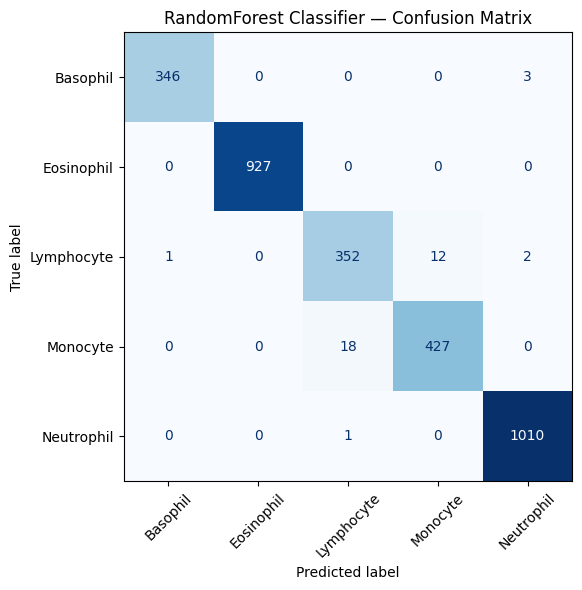

In [18]:
model = models["RandomForest Classifier"]
y_pred = model.predict(X_test_encoded)

show_performance(
    "RandomForest Classifier",
    lb_encoder.inverse_transform(y_test),
    lb_encoder.inverse_transform(y_pred)
)


ExtraTrees Classifier — Classification Report

              precision    recall  f1-score   support

    Basophil     0.9971    0.9914    0.9943       349
  Eosinophil     1.0000    1.0000    1.0000       927
  Lymphocyte     0.9488    0.9591    0.9539       367
    Monocyte     0.9727    0.9596    0.9661       445
  Neutrophil     0.9951    0.9990    0.9970      1011

    accuracy                         0.9881      3099
   macro avg     0.9827    0.9818    0.9823      3099
weighted avg     0.9881    0.9881    0.9881      3099



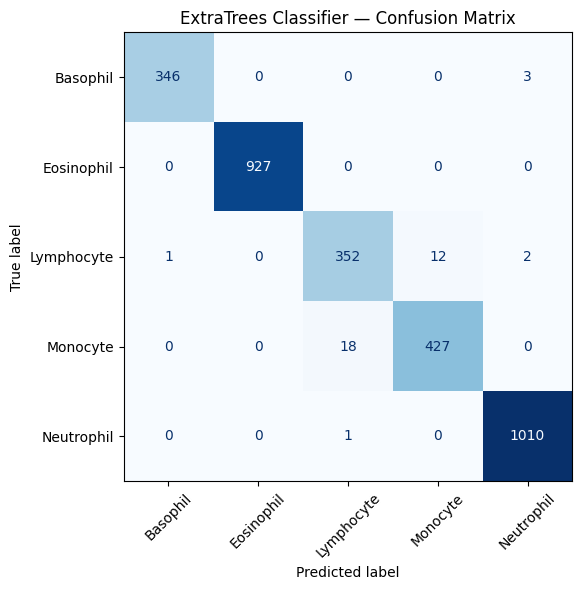

In [19]:
model = models["ExtraTrees Classifier"]
y_pred = model.predict(X_test_encoded)

show_performance(
    "ExtraTrees Classifier",
    lb_encoder.inverse_transform(y_test),
    lb_encoder.inverse_transform(y_pred)
)


Hist Classifier — Classification Report

              precision    recall  f1-score   support

    Basophil     0.9943    1.0000    0.9971       349
  Eosinophil     1.0000    1.0000    1.0000       927
  Lymphocyte     0.9541    0.9619    0.9579       367
    Monocyte     0.9727    0.9618    0.9672       445
  Neutrophil     1.0000    1.0000    1.0000      1011

    accuracy                         0.9900      3099
   macro avg     0.9842    0.9847    0.9845      3099
weighted avg     0.9900    0.9900    0.9900      3099



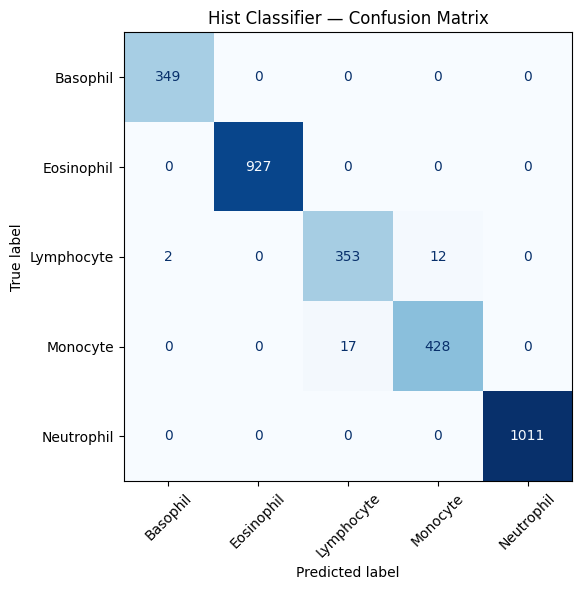

In [20]:
model = models["Hist Classifier"]
y_pred = model.predict(X_test_encoded)

show_performance(
    "Hist Classifier",
    lb_encoder.inverse_transform(y_test),
    lb_encoder.inverse_transform(y_pred)
)


XGB Classifier — Classification Report

              precision    recall  f1-score   support

    Basophil     0.9971    0.9914    0.9943       349
  Eosinophil     1.0000    1.0000    1.0000       927
  Lymphocyte     0.9489    0.9619    0.9553       367
    Monocyte     0.9727    0.9596    0.9661       445
  Neutrophil     0.9961    0.9990    0.9975      1011

    accuracy                         0.9884      3099
   macro avg     0.9830    0.9824    0.9826      3099
weighted avg     0.9884    0.9884    0.9884      3099



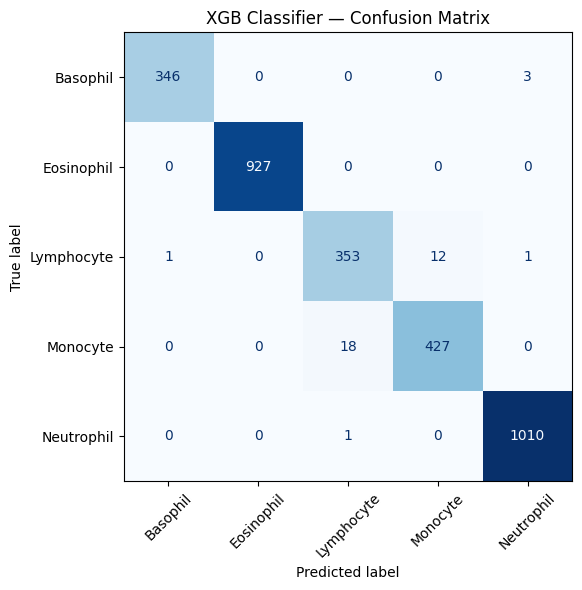

In [21]:
model = models["XGB Classifier"]
y_pred = model.predict(X_test_encoded)

show_performance(
    "XGB Classifier",
    lb_encoder.inverse_transform(y_test),
    lb_encoder.inverse_transform(y_pred)
)

In [26]:
best = (
    results_df[results_df["Split"] == "Validation"]
    .sort_values("Macro F1", ascending=False).iloc[0]
)

selected_name = best["Model"]
best_model = models[selected_name]

print(f"Best model: {selected_name}")
print(f"highest validation Macro-F1 : {best['Macro F1']:.4f}")

display(
    results_df.loc[
        results_df["Model"] == selected_name,
        ["Split", "Accuracy", "Macro F1", "Training Time (s)"]
    ].round(4)
)

Best model: Logistic Regression
highest validation Macro-F1 : 0.9830


,Split,Accuracy,Macro F1,Training Time (s)
0,Train,0.9909,0.9861,0.0596
1,Validation,0.9883,0.9830,0.0596
2,Test,0.9890,0.9838,0.0596
